In [1]:
import pandas as pd

Delivery_data = pd.read_csv(
    r"D:\EXCELR OFFLINE\Python\project Delivery delay pred\DataCoSupplyChainDataset.csv",
    encoding="ISO-8859-1"
)

Delivery_data.shape

(180519, 53)

In [4]:
#Separate inputs (X) and target (y)
features = [
    'Type',
    'Days for shipment (scheduled)',
    'Category Name',
    'Customer Segment',
    'Market',
    'Order Region',
    'Shipping Mode',
    'Order Item Discount',
    'Order Item Quantity',
    'Sales'
]

X = Delivery_data[features]
y = Delivery_data['Late_delivery_risk']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (180519, 10)
y shape: (180519,)


In [5]:
#Split training and testing data
#We keep 80% of the data for training and 20% for testing the model on unseen records.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(144415, 10) (36104, 10)


In [6]:
#Convert text categories into numbers
#Concept: One-Hot Encoding
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(144415, 93)
(36104, 93)


In [7]:
#Train the Machine Learning Model
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_processed, y_train)

print("Model training completed!")

Model training completed!


In [8]:
#Evaluate the Model
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_processed)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6966541103478839
              precision    recall  f1-score   support

           0       0.62      0.88      0.72     16308
           1       0.84      0.55      0.66     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.69     36104
weighted avg       0.74      0.70      0.69     36104



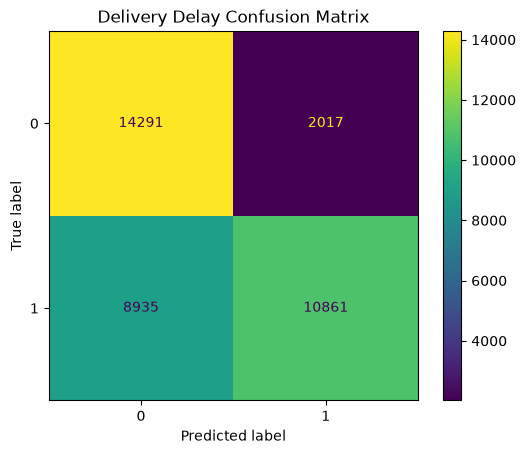

In [9]:
#View the Confusion Matrix
#Concept: Classification Evaluation
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Delivery Delay Confusion Matrix")
plt.show()

In [10]:
#Save the Model and Preprocessor
import joblib

joblib.dump(model, 'delivery_delay_model.pkl')
joblib.dump(preprocessor, 'delivery_preprocessor.pkl')

print("Model and preprocessor saved!")

Model and preprocessor saved!


In [11]:
input_options = {
    col: sorted(Delivery_data[col].dropna().astype(str).unique())
    for col in cat_cols
}

joblib.dump(input_options, 'delivery_input_options.pkl')

print("Input options saved!")

Input options saved!


In [ ]:
#Create the Streamlit app (app.py)
